# Editor and inspector plugins: the flow

**The idea:** you never call a plugin's functions yourself. You **register** the plugin once, and from then on the editor calls your hooks at the right moments.

There are three flows to know. B and C both sit inside A.

| Flow | Question it answers | Section |
|---|---|---|
| **A. Plugin flow** | When does my plugin load, and when does it go away? | 2 |
| **B. Inspector flow** | What happens every time I select something? | 3, 4 |
| **C. Main-screen flow** | How do I get my own tab in the middle, with buttons that follow the selection? | 6 |

| Section | Contents |
|---|---|
| 1 | Who is who |
| 2 | Flow A: the life of an `EditorPlugin` |
| 3 | Flow B: what the Inspector does on every selection |
| 4 | Inside `_parse_property` |
| 5 | Your mover plugin, traced end to end |
| 6 | Flow C: the main screen, and buttons that follow the selection |
| 7 | A toy Inspector you can run |
| 8 | Which hook for which job, and what bites |
| 9 | What my project registers today (runnable) |

Examples come from `addons/_rpgm_v2/`. Related: `godot-editor-as-a-toolbox`, `godot-gotchas-and-best-practices`.


## 1. Who is who

| Piece | What it is | Is a Node? | Its lifecycle |
|---|---|---|---|
| `EditorPlugin` (`plugin.gd`) | The entry point of an addon. It registers everything else | Yes | Full node lifecycle: `_init`, `_enter_tree`, `_ready`, `_exit_tree` |
| `EditorInspectorPlugin` (`inspector/inspector_plugin.gd`) | A helper the Inspector consults while building its list | No | Only `_init`, when `plugin.gd` calls `.new()`. Then it waits to be called |
| The Inspector | The built-in dock that lists an object's properties | Yes (part of the editor) | Rebuilds its whole list on every selection |
| `object` | Whatever the Inspector is showing right now | Depends | It is the real live object from the scene you are editing |
| Controls you create (buttons, rows, panels) | Ordinary `Control` nodes | Yes | Enter the editor's tree when added; freed when the Inspector rebuilds |

Same rule as in the game: a Node gets the tree callbacks, anything else only gets `_init`. That is the editor being a Godot app.


## 2. Flow A: the life of an `EditorPlugin`

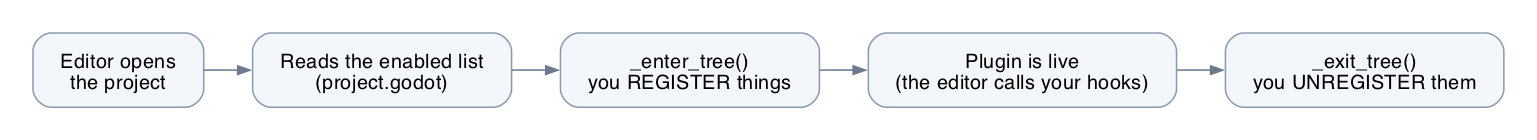

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  nodesep=0.3; ranksep=0.45;
  open [label="Editor opens\nthe project"];
  list [label="Reads the enabled list\n(project.godot)"];
  enter [label="_enter_tree()\nyou REGISTER things"];
  live [label="Plugin is live\n(the editor calls your hooks)"];
  exit [label="_exit_tree()\nyou UNREGISTER them"];
  open -> list -> enter -> live -> exit;
}
```

</details>

| Step | What happens | In your addon |
|---|---|---|
| 1 | The editor opens the project and reads which addons are enabled | `project.godot` lists `res://addons/_rpgm_v2/plugin.cfg` |
| 2 | It reads `plugin.cfg` to find the script | `script="plugin.gd"` |
| 3 | It creates the plugin node and adds it to the editor's tree, so `_enter_tree()` runs | `_enter_tree` in `plugin.gd` |
| 4 | Inside `_enter_tree` you register things with the editor | `add_inspector_plugin(mover_inspector)`, `add_control_to_bottom_panel(panel, "_rpgm_v2")`, and the main screen (section 6) |
| 5 | The plugin is live. The editor now calls your hooks when it needs them | The Inspector starts consulting `mover_inspector` |
| 6 | You disable the plugin or close the editor, so `_exit_tree()` runs | `_exit_tree` in `plugin.gd` |
| 7 | Inside `_exit_tree` you take back everything you registered | `remove_inspector_plugin`, `remove_control_from_bottom_panel`, `panel.queue_free()` |

**Register and unregister come in pairs:**

| In `_enter_tree` | In `_exit_tree` |
|---|---|
| `add_inspector_plugin(x)` | `remove_inspector_plugin(x)` |
| `add_control_to_bottom_panel(panel, title)` | `remove_control_from_bottom_panel(panel)` + `panel.queue_free()` |
| `add_dock(dock)` | `remove_dock(dock)` + `dock.queue_free()` |
| `add_tool_menu_item(name, callable)` | `remove_tool_menu_item(name)` |

Steps 3 to 7 also run when you turn the plugin off and on in Project Settings > Plugins, which is how you reload it after editing its code.


## 3. Flow B: what the Inspector does on every selection

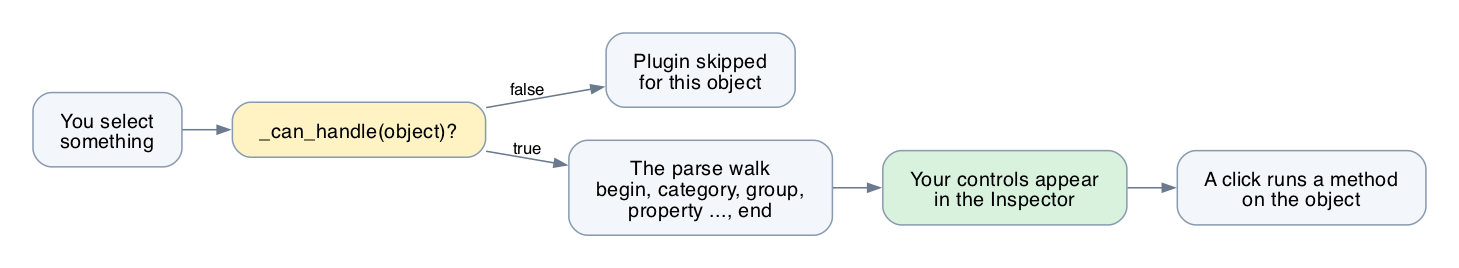

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  nodesep=0.3; ranksep=0.45;
  sel [label="You select\nsomething"];
  can [label="_can_handle(object)?", fillcolor="#fff3c4"];
  skip [label="Plugin skipped\nfor this object"];
  walk [label="The parse walk\nbegin, category, group,\nproperty ..., end"];
  shown [label="Your controls appear\nin the Inspector", fillcolor="#d9f2dd"];
  click [label="A click runs a method\non the object"];
  sel -> can;
  can -> skip [label="false"];
  can -> walk [label="true"];
  walk -> shown -> click;
}
```

</details>

**What `object` is, and when it is passed in:**

| Trigger | `object` is |
|---|---|
| You select a node in the Scene dock | That node (an event, the player) |
| You open a `.tres` file from the FileSystem dock | That resource |
| You expand a resource inside the Inspector, such as a lambda in `on_action` | That inner resource, with its own separate round of calls |
| The selected object's property list changes, or you undo | The same object again |

A class and an instance are different things here. A `.gd` file is a `GDScript` resource (the recipe); an event on the map is an instance made from it. Inspector plugins act on instances.

**The walk.** The Inspector asks `_can_handle(object)` on **every** registered inspector plugin, for **every** object it shows. For each plugin that answers `true`:

| Step | The Inspector calls | You can |
|---|---|---|
| 1 | `_parse_begin(object)` | Add controls at the very top |
| 2 | `_parse_category(object, name)` at each category header | Add controls under that header |
| 3 | `_parse_group(object, name)` at each group | Add controls under that group |
| 4 | `_parse_property(object, type, name, ...)` once per property, in display order | Add a control at that spot, or replace the property's editor |
| 5 | `_parse_end(object)` | Add controls at the very bottom |

It is a walk down the Inspector from top to bottom. Each call is your chance to insert something **at that point**, which is why a control added while parsing `map_position` lands right above `map_position`.

You only write the hooks you need. `_can_handle` plus one parse hook is a complete inspector plugin.

**The hooks do not all have the same shape.** Only `_parse_property` knows about a single property and returns a value:

| Hook | Receives | Returns |
|---|---|---|
| `_parse_begin(object)` | The object only | nothing |
| `_parse_category(object, category)` | The object and the category name | nothing |
| `_parse_group(object, group)` | The object and the group name | nothing |
| `_parse_property(object, type, name, ...)` | The object and one property's details | `bool` (hide the default editor?) |
| `_parse_end(object)` | The object only | nothing |

So a `_parse_begin` that puts the button row at the very top has no `name` to test and nothing to return:

```gdscript
func _parse_begin(object: Object) -> void:
	var box := HBoxContainer.new()
	box.add_child(_make_button("Quantise via Map", Callable(object, "_quantise_via_map_position")))
	box.add_child(_make_button("Quantise via Global", Callable(object, "_quantise_via_global_position")))
	add_custom_control(box)
```


## 4. Inside `_parse_property`

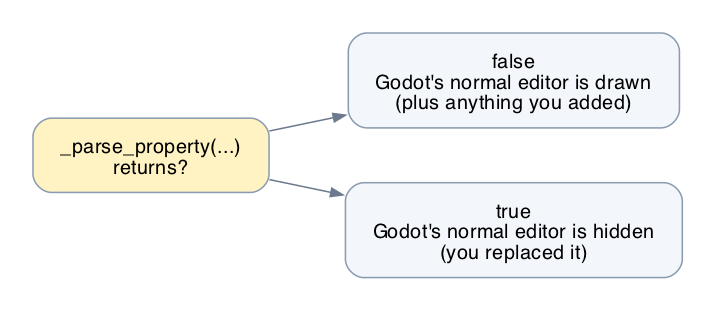

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  q [label="_parse_property(...)\nreturns?", fillcolor="#fff3c4"];
  keep [label="false\nGodot's normal editor is drawn\n(plus anything you added)"];
  hide [label="true\nGodot's normal editor is hidden\n(you replaced it)"];
  q -> keep;
  q -> hide;
}
```

</details>

**The arguments describe the one property being drawn:**

| Argument | Meaning | For `map_position` |
|---|---|---|
| `object` | The object being inspected | The selected mover |
| `type` | The property's Variant type | `TYPE_VECTOR2I` |
| `name` | The property's name | `"map_position"` |
| `hint_type`, `hint_string` | Its export hint (range, enum, file...) | none |
| `usage_flags` | How it is used (stored, shown in editor...) | the usual export flags |
| `wide` | Whether the Inspector is in its wide layout | varies |

**What you can do while handling it:**

| Call | Effect |
|---|---|
| `add_custom_control(node)` | Puts your control on its own row at the current position |
| `add_property_editor(name, editor)` | Supplies a custom editor widget (an `EditorProperty`) for the property itself |
| `return false` | Godot still draws its normal editor for this property |
| `return true` | Godot's normal editor for this property is skipped |

| You want | Do |
|---|---|
| Extra buttons next to a property | `add_custom_control(...)`, return `false` (your plugin) |
| A completely different editor for a property | `add_property_editor(...)`, return `true` |
| To hide a property | Add nothing, return `true` |
| To leave a property alone | Return `false` straight away |


## 5. Your mover plugin, traced end to end

| Step | What happens | Where |
|---|---|---|
| 1 | The editor loads the addon; `_enter_tree` registers `mover_inspector` | `_enter_tree` in `addons/_rpgm_v2/plugin.gd` |
| 2 | You click an event on the map. The Inspector starts rebuilding | (editor) |
| 3 | It asks `_can_handle(event)`. An event extends `_RPGM_Mover`, so the answer is `true` | `_can_handle` in `inspector/inspector_plugin.gd` |
| 4 | It calls `_parse_property` for each property. All but one return `false` at once | first line of `_parse_property` |
| 5 | At `map_position`, the plugin builds an `HBoxContainer` with two buttons | `_parse_property` |
| 6 | `add_custom_control(box)` inserts the row above `map_position`; `return false` keeps the normal `map_position` editor | last two lines of `_parse_property` |
| 7 | You click "Quantise via Map". The button's `pressed` signal calls `_quantise_via_map_position()` on the selected event | `_rpgm_mover.gd` |
| 8 | You select something else. The row is freed; the walk starts again for the new object | (editor) |
| **Result** | **A row of buttons that exists only while a mover is selected, wired to that mover** | |

Two things make step 7 work:

| Requirement | Why |
|---|---|
| `Callable(object, "_quantise_via_map_position")` is built during the walk | It binds the button to the object selected **right now** |
| `_rpgm_mover.gd` starts with `@tool` | Without it, the mover's methods do not run in the editor and the click does nothing |


## 6. Flow C: the main screen

The middle of the editor, where 2D / 3D / Script are shown, is called the **main screen**.

**Where each kind of addition goes.** Everything is registered through an `EditorPlugin`:

| Area | Called | Added with |
|---|---|---|
| Bottom | Bottom panel | `add_control_to_bottom_panel` |
| Sides | Docks | `add_dock` |
| Right, inside the property list | Inspector | An `EditorInspectorPlugin`, via `add_inspector_plugin` |
| Middle | Main screen | Five hooks on the `EditorPlugin` itself (below) |

### 6.1 Your own tab

| Hook on the plugin | What it tells the editor |
|---|---|
| `_has_main_screen() -> bool` | "Give me a tab" |
| `_get_plugin_name() -> String` | The tab's label (yours says "Events") |
| `_get_plugin_icon() -> Texture2D` | The tab's icon |
| `_make_visible(visible)` | Called on every tab switch; show or hide your screen |
| `_enter_tree` / `_exit_tree` | Add your screen to `EditorInterface.get_editor_main_screen()`, and free it |

| Step | What happens |
|---|---|
| 1 | In `_enter_tree` you instance your screen, add it to the main screen, and hide it |
| 2 | The editor sees `_has_main_screen()` is `true` and adds a tab named by `_get_plugin_name()` |
| 3 | You click the tab. The editor calls `_make_visible(true)` on your plugin and `false` on the others |
| 4 | Your screen fills the middle until you switch away |
| **Result** | **A tab that sits next to 2D / 3D / Script as an equal** |

**These hooks cannot be delegated.** The inspector and the bottom panel are things you *hand over* to the editor. A main-screen tab is something the editor *asks your plugin about*, and it only asks plugins it loaded itself.

| Where the five hooks are | Works? | Why |
|---|---|---|
| In `plugin.gd`, the script your `plugin.cfg` names | Yes | The editor loaded it, so it asks it |
| In a separate script with its own `plugin.cfg`, enabled in Project Settings | Yes | It is simply a second plugin |
| In a separate script created with `.new()` from `plugin.gd` | **No** | The editor does not know it exists; its `_enter_tree` never even runs |

The screen's *content* (its `.tscn` and script) can live in any file. Only the five hooks have to be on the plugin.

### 6.2 Buttons that follow the selection

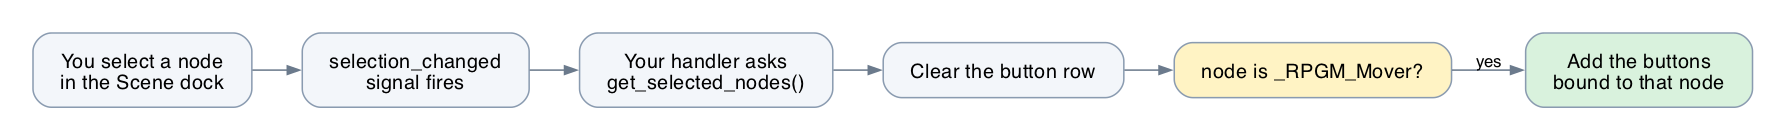

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  nodesep=0.3; ranksep=0.45;
  sel [label="You select a node\nin the Scene dock"];
  sig [label="selection_changed\nsignal fires"];
  ask [label="Your handler asks\nget_selected_nodes()"];
  q [label="node is _RPGM_Mover?", fillcolor="#fff3c4"];
  clear [label="Clear the button row"];
  build [label="Add the buttons\nbound to that node", fillcolor="#d9f2dd"];
  sel -> sig -> ask -> clear -> q;
  q -> build [label="yes"];
}
```

</details>

There is no `_can_handle` for the main screen. You do that job yourself: listen for the selection changing, look at what is selected, rebuild the buttons. This goes in the screen's own script. It is a sketch; I have not run it in your editor.

```gdscript
@tool
extends Control

@onready var button_row : HBoxContainer = %ButtonRow   # an empty HBoxContainer in the scene

func _ready() -> void:
	EditorInterface.get_selection().selection_changed.connect(_on_selection_changed)
	_on_selection_changed()

func _on_selection_changed() -> void:
	for child in button_row.get_children(): child.queue_free()

	var nodes := EditorInterface.get_selection().get_selected_nodes()
	if nodes.size() != 1: return
	var node := nodes[0]

	if node is _RPGM_Mover:
		_add_button("Quantise via Map", node._quantise_via_map_position)
		_add_button("Quantise via Global", node._quantise_via_global_position)

func _add_button(text : String, callback : Callable) -> void:
	var button := Button.new()
	button.text = text
	button.pressed.connect(callback)
	button_row.add_child(button)
```

**The same job, in the Inspector and on the main screen:**

| Step | Inspector plugin (flow B) | Main screen (flow C) |
|---|---|---|
| 1 | The Inspector calls `_can_handle(object)` on every selection | You connect to `selection_changed` once, in `_ready` |
| 2 | `object` is handed to you | You ask for it: `get_selection().get_selected_nodes()` |
| 3 | `object is _RPGM_Mover` | `node is _RPGM_Mover` |
| 4 | The Inspector frees your controls and rebuilds | You clear the row and rebuild it yourself |
| 5 | `add_custom_control(box)` | `button_row.add_child(button)` |
| **Result** | **Buttons inside the property list** | **Buttons on your own tab** |

| Thing to know | Why it matters |
|---|---|
| The screen's script needs `@tool` | Without it the buttons are drawn but `_ready` never runs, so nothing is connected |
| You get a list, not one object | Several nodes can be selected; decide whether to require one or act on all |
| Only scene nodes are in the list | A lambda expanded in the Inspector is not a node and will not appear |
| The tab must be showing | The main screen replaces the 2D view while its tab is active. For buttons you can reach while looking at the map, use the 2D toolbar: `add_control_to_container(CONTAINER_CANVAS_EDITOR_MENU, control)` |
| Avoid `_handles(object)` / `_edit(object)` on a plugin that owns a tab | They make the editor jump to your tab whenever a matching node is selected, the way clicking a script opens the Script view (section 6.3) |


### Feel it: the selection signal

In [1]:
class Signal:
	def __init__(self): self.listeners = []
	def connect(self, fn): self.listeners.append(fn)
	def emit(self):
		for fn in self.listeners: fn()

class Mover:
	def __init__(self, name): self.name = name
class Label:
	def __init__(self, name): self.name = name

selected, selection_changed = [], Signal()            # what the editor owns

button_row = []                                       # what your screen owns
def on_selection_changed():
	button_row.clear()                                # clear ...
	if len(selected) != 1: return
	node = selected[0]
	if isinstance(node, Mover):                       # ... then rebuild for this node
		button_row.extend([f"[Quantise via Map -> {node.name}]", f"[Quantise via Global -> {node.name}]"])

selection_changed.connect(on_selection_changed)       # done once, in _ready

def select(*nodes):
	selected[:] = nodes
	selection_changed.emit()                          # the editor does this for you
	print(f"selected {[n.name for n in nodes]!s:<28} main screen shows: {button_row or '(no buttons)'}")

select(Mover("_npc_0_1"))
select(Label("Title"))
select(Mover("_npc_0_1"), Mover("Player"))
select(Mover("Player"))

selected ['_npc_0_1']                 main screen shows: ['[Quantise via Map -> _npc_0_1]', '[Quantise via Global -> _npc_0_1]']
selected ['Title']                    main screen shows: (no buttons)
selected ['_npc_0_1', 'Player']       main screen shows: (no buttons)
selected ['Player']                   main screen shows: ['[Quantise via Map -> Player]', '[Quantise via Global -> Player]']


In [2]:
# ----- student scratchpad -----

### 6.3 Why not `_handles` and `_edit`?

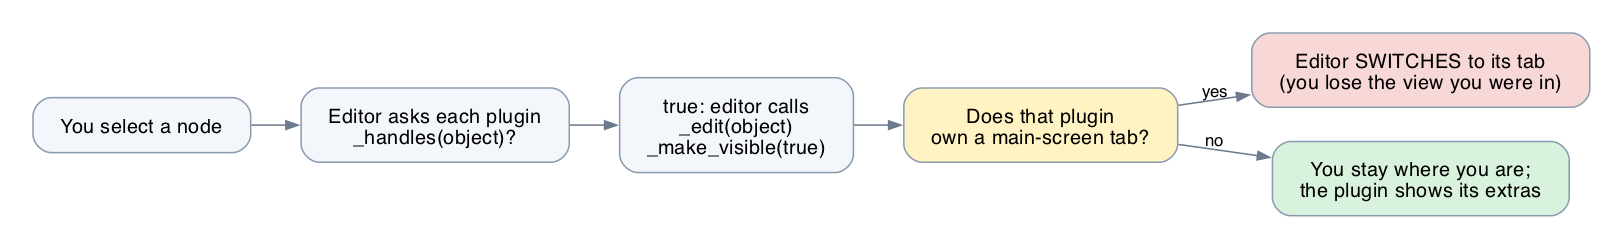

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  nodesep=0.3; ranksep=0.45;
  sel [label="You select a node"];
  ask [label="Editor asks each plugin\n_handles(object)?"];
  yes [label="true: editor calls\n_edit(object)\n_make_visible(true)"];
  q [label="Does that plugin\nown a main-screen tab?", fillcolor="#fff3c4"];
  jump [label="Editor SWITCHES to its tab\n(you lose the view you were in)", fillcolor="#f8d7d7"];
  stay [label="You stay where you are;\nthe plugin shows its extras", fillcolor="#d9f2dd"];
  sel -> ask -> yes -> q;
  q -> jump [label="yes"];
  q -> stay [label="no"];
}
```

</details>

`EditorPlugin` has two hooks that look like the main screen's version of `_can_handle`:

| Hook | The editor calls it | You answer / do |
|---|---|---|
| `_handles(object) -> bool` | For each plugin, whenever something is selected | `true` if this plugin deals with that kind of object |
| `_edit(object)` | Right after a `true`, with the selected object | Remember the object; set up your UI for it |
| `_make_visible(visible)` | `true` after `_edit`, `false` when the selection moves on | Show or hide your UI |

They are a real, supported route. The catch is what `_make_visible(true)` means for a plugin that owns a tab: **it means "bring my tab to the front".** That is exactly how selecting a script opens the Script view, and how selecting a 3D node switches to the 3D view.

**What happens when you select a mover, by kind of plugin:**

| Step | Plugin WITH a main-screen tab, using `_handles` | Plugin WITHOUT a tab, using `_handles` | Any plugin, using `selection_changed` |
|---|---|---|---|
| 1 | Editor asks `_handles(mover)`: `true` | Editor asks `_handles(mover)`: `true` | The signal fires |
| 2 | Editor calls `_edit(mover)` | Editor calls `_edit(mover)` | Your handler reads the selection |
| 3 | Editor calls `_make_visible(true)` and **switches the main screen to your tab** | Editor calls `_make_visible(true)`; your toolbar buttons or overlay appear | You rebuild your buttons |
| 4 | The 2D view you were working in is gone | You are still in the 2D view | You are still wherever you were |
| **Result** | **Every click on an event throws you out of the map** | **Extras appear in place** | **Your tab updates quietly in the background** |

| You want | Use | Why |
|---|---|---|
| Buttons on your own tab that follow the selection | `selection_changed` (section 6.2) | No tab switching |
| Your tab to open automatically when a certain thing is selected | `_handles` + `_edit` on the plugin that owns the tab | That jump is the feature (the Script view does this) |
| Toolbar buttons or drawing over the 2D view for certain nodes | `_handles` + `_edit` + `_make_visible` on a plugin **without** a tab | The standard route for in-place extras; `_handles` is also what switches on the 2D overlay hooks |
| Both a tab and in-place extras | The signal for everything, or split into two plugins | One plugin's `_make_visible` can only mean one thing |

Your `_rpgm_v2` plugin owns the "Events" tab, so for it `_handles` would mean a jump on every event click. That is the reason section 6.2 uses the signal.

This describes Godot's behaviour as I understand it; I have not run a `_handles` plugin in your editor to watch the jump.


### Feel it: the jump

In [3]:
class Plugin:
	def __init__(self, name, tab=None, handles=None): self.name, self.tab, self.kind = name, tab, handles
	def handles(self, obj): return self.kind is not None and obj["type"] == self.kind

def select(obj, plugins, main_screen):
	for plugin in plugins:
		if not plugin.handles(obj): continue
		if plugin.tab:
			main_screen = plugin.tab                     # _make_visible(true) on a tab owner
			print(f"   {plugin.name}: _handles -> true, editor switches to '{plugin.tab}'")
		else:
			print(f"   {plugin.name}: _handles -> true, shows its extras in place")
	return main_screen

built_in = [Plugin("2D editor", tab="2D", handles="Node2D"), Plugin("Script editor", tab="Script", handles="Script")]

for title, yours in {
	"your plugin owns a tab AND uses _handles": Plugin("_rpgm_v2", tab="Events", handles="Mover"),
	"your plugin has no tab, uses _handles":    Plugin("_rpgm_toolbar", handles="Mover"),
	"your plugin owns a tab, uses the signal":  Plugin("_rpgm_v2", tab="Events"),
}.items():
	print(title)
	screen = select({"name": "_npc_0_1", "type": "Mover"}, built_in + [yours], main_screen="2D")
	print(f"   you were on '2D', you are now on '{screen}'\n")

your plugin owns a tab AND uses _handles
   _rpgm_v2: _handles -> true, editor switches to 'Events'
   you were on '2D', you are now on 'Events'

your plugin has no tab, uses _handles
   _rpgm_toolbar: _handles -> true, shows its extras in place
   you were on '2D', you are now on '2D'

your plugin owns a tab, uses the signal
   you were on '2D', you are now on '2D'



In [4]:
# ----- student scratchpad -----

## 7. A toy Inspector

The same flow in plain Python. Flip `HIDE_DEFAULT`, add a property, or write a second plugin.

In [5]:
class Mover:
	def __init__(self, name): self.name = name; self.properties = ["position", "map_position", "facing"]
class Lambda:
	def __init__(self, name): self.name = name; self.properties = ["messages"]

HIDE_DEFAULT = False      # what _parse_property returns for map_position

class MoverInspectorPlugin:
	def can_handle(self, obj): return isinstance(obj, Mover)
	def parse_begin(self, obj, rows): pass
	def parse_property(self, obj, name, rows):
		if name != "map_position": return False
		rows.append(f"[Quantise via Map] [Quantise via Global]      <- added by the plugin, bound to {obj.name}")
		return HIDE_DEFAULT
	def parse_end(self, obj, rows): pass

def inspect(obj, plugins):
	print(f"select {obj.name}")
	handling = []
	for plugin in plugins:
		answer = plugin.can_handle(obj)
		print(f"   _can_handle({obj.name}) -> {answer}")
		if answer: handling.append(plugin)

	rows = []
	for plugin in handling: plugin.parse_begin(obj, rows)
	for name in obj.properties:                       # top to bottom
		hidden = False
		for plugin in handling:
			hidden = plugin.parse_property(obj, name, rows) or hidden
		if not hidden: rows.append(f"{name}: (normal editor)")
	for plugin in handling: plugin.parse_end(obj, rows)

	print("   Inspector shows:")
	for row in rows: print("      " + row)
	print()

registered = [MoverInspectorPlugin()]                 # what add_inspector_plugin does
inspect(Mover("_npc_0_1"), registered)
inspect(Lambda("Show Messages"), registered)

select _npc_0_1
   _can_handle(_npc_0_1) -> True
   Inspector shows:
      position: (normal editor)
      [Quantise via Map] [Quantise via Global]      <- added by the plugin, bound to _npc_0_1
      map_position: (normal editor)
      facing: (normal editor)

select Show Messages
   _can_handle(Show Messages) -> False
   Inspector shows:
      messages: (normal editor)



In [6]:
# ----- student scratchpad -----

## 8. Which hook for which job, and what bites

| I want... | Flow | Use |
|---|---|---|
| A button row next to one property | B | `_parse_property` + `add_custom_control` |
| Buttons at the top of the Inspector for a type | B | `_parse_begin` + `add_custom_control` |
| A custom editor for one kind of value | B | `_parse_property` + `add_property_editor`, return `true` |
| A simple one-off button with no layout | neither | `@export_tool_button` on the node itself |
| A panel at the bottom or a dock at the side | A | `add_control_to_bottom_panel` / `add_dock` in `_enter_tree` |
| My own tab next to 2D / 3D / Script | C | The five main-screen hooks on the plugin (section 6.1) |
| Buttons on that tab that depend on the selected node | C | `selection_changed` + rebuild (section 6.2) |
| Buttons in the 2D view's toolbar | A | `add_control_to_container(CONTAINER_CANVAS_EDITOR_MENU, control)` |
| A menu entry under Project > Tools | A | `add_tool_menu_item` in `_enter_tree` |
| A keyboard shortcut | A | `_input` on the `EditorPlugin` (your copy-with-path addon) |
| To react when the selection changes | A | Connect to `EditorInterface.get_selection().selection_changed` in `_enter_tree` |

| Gotcha | What you see | Avoid it by |
|---|---|---|
| The target script has no `@tool` | Buttons appear but clicking does nothing, or errors | `@tool` on any script whose methods the editor calls |
| A panel or screen script has no `@tool` | The panel is drawn but its `_ready` never runs, so its buttons are not connected | `@tool` on the scripts of scenes your plugin shows |
| An `EditorPlugin` made with `.new()` | Its tab never appears and its `_enter_tree` never runs | Keep the main-screen hooks on the script `plugin.cfg` names |
| Changes made by a button skip undo | Cmd+Z does not revert them | Go through `EditorUndoRedoManager` |
| Keeping state on controls you added | It vanishes on the next selection | The Inspector frees and rebuilds them; keep state on the plugin or the object |
| Nothing removed in `_exit_tree` | Duplicate panels after each reload | Pair every `add_...` with its `remove_...` |
| You edited the plugin and nothing changed | Old behaviour | Toggle the plugin off and on |
| `_can_handle` too broad (`return true`) | Your controls show up on every object | Check the type, as your plugin does |

Every hook and method named in this notebook exists in your installed Godot build (checked against the binary). I have not run them beyond what your addon already does.


## 9. What my project registers today

Reads `project.godot` and the enabled addons' scripts (read-only).

In [7]:
import os, re

root = os.getcwd()
while not os.path.exists(os.path.join(root, "project.godot")) and root != "/":
	root = os.path.dirname(root)

project = open(os.path.join(root, "project.godot")).read()
enabled = re.findall(r'res://(addons/[^"]+)/plugin\.cfg', project)

for addon in enabled:
	print(addon)
	for folder, _, names in os.walk(os.path.join(root, addon)):
		for name in sorted(n for n in names if n.endswith(".gd")):
			text = open(os.path.join(folder, name), errors="ignore").read()
			base = re.search(r"^extends (\w+)", text, re.M)
			rel = os.path.relpath(os.path.join(folder, name), os.path.join(root, addon))
			print(f"   {rel:<52} extends {base.group(1) if base else '?'}")
			for call in sorted(set(re.findall(r"\b(add_(?:inspector_plugin|control_to_bottom_panel|dock|tool_menu_item|custom_control|property_editor|context_menu_plugin))\(", text))):
				print(f"      registers / adds: {call}")
			hooks = sorted(set(re.findall(r"^func (_can_handle|_parse_\w+|_enter_tree|_exit_tree|_input)\(", text, re.M)))
			if hooks: print(f"      hooks defined:    {', '.join(hooks)}")
	print()

addons/_rpgm_v2
   _rpgm_v2.gd                                          extends Control
   plugin.gd                                            extends EditorPlugin
      registers / adds: add_control_to_bottom_panel
      registers / adds: add_inspector_plugin
      hooks defined:    _enter_tree, _exit_tree
   inspector/inspector_plugin.gd                        extends EditorInspectorPlugin
      registers / adds: add_custom_control
      hooks defined:    _can_handle, _parse_begin, _parse_property
   bottom_dock/bottom_plugin.gd                         extends Node

addons/copy_with_path
   plugin.gd                                            extends EditorPlugin
      hooks defined:    _input



In [8]:
# ----- student scratchpad -----